<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/00_start_here/00_welcome.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧭 Welcome to ML Quest: from your first model to the leaderboard

> *"The best way to learn machine learning is to do machine learning, on real problems, against a real scoreboard."*

You are about to start an adventure. Each notebook in this repository is a **quest**: a real problem, a story behind it,
a few concepts to master, and a scoreboard telling you how well you did. By the end you will have touched almost every
family of problems you will meet in competitions on **Zindi**, **Kaggle**, **DrivenData** or in a real job:

| Track | You will learn to… | Famous ancestors |
|---|---|---|
| 📊 **Tabular** | predict a class or a number from a spreadsheet | Titanic, Netflix Prize, House Prices |
| ⏳ **Time series** | forecast the future, recognise patterns in signals, spot anomalies | M-competitions, Keeling curve, NAB |
| 👁️ **Computer vision** | classify, detect, segment, track keypoints in images and videos | ImageNet 2012, COCO, Cityscapes |
| 💬 **NLP** | classify text, find entities, search by meaning, generate text | Masakhane, BERT, GPT |
| 🔊 **Audio** | recognise sounds and transcribe speech | Bell Labs' *Audrey* (1952), Whisper |

This first notebook checks that your machine is ready and tells you **how competitions work**, a short history included.

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

## 1. Is my laptop ready? 🩺

The cell below prints your Python version, your operating system, the version of the main libraries and the
**device** your models will train on:

- `cuda` → you have an NVIDIA GPU. Lucky you, deep learning will fly. 🚀
- `mps` → you have an Apple Silicon Mac (M1/M2/M3/M4…). PyTorch uses its GPU through *Metal*. 🍏
- `cpu` → no GPU: no problem! Every notebook is sized to run on a laptop CPU, just a bit slower. 🐢

If a library shows ✘, go back to the [installation guide](../INSTALL.md) and run `uv sync --all-groups`.

In [2]:
quest("Prepare your gear", chapter="Chapter 0 · Start here", xp=50)
system_report(packages=(
    "numpy", "pandas", "scikit-learn", "matplotlib",          # core
    "lightgbm", "xgboost", "catboost", "optuna",               # tabular
    "statsmodels", "aeon", "chronos-forecasting",               # time series
    "torch", "torchvision", "timm", "ultralytics",              # vision
    "transformers", "sentence-transformers",                    # NLP
    "librosa",                                                  # audio
))

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Prepare your gear
   Chapter 0 · Start here
   Reward: up to 50 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🐍 Python   3.12.13  (.venv/bin/python)
💻 System   Darwin 25.6.0 · arm64
📁 Repo     Machine-Learning-Tutorials-Updated
   ✔ numpy                      2.3.5
   ✔ pandas                     3.0.6
   ✔ scikit-learn               1.9.1
   ✔ matplotlib                 3.11.2
   ✔ lightgbm                   4.7.0
   ✔ xgboost                    3.4.1
   ✔ catboost                   1.2.10
   ✔ optuna                     5.1.0
   ✔ statsmodels                0.15.0
   ✔ aeon                       1.6.0
   ✔ chronos-forecasting        2.3.2
   ✔ torch                      2.15.0
   ✔ torchvision                0.29.2
   ✔ timm                       1.0.31
   ✔ ultralytics                8.4.216
   ✔ transformers               5.23.0

In [3]:
checkpoint("welcome/setup", xp=50, msg="your environment works!")

✅ Checkpoint · welcome/setup (+50 XP) your environment works!
   ████████████░░░░░░░░░░░░ 50/100 XP


## 2. A (very) short history of machine learning competitions 📜

Competitions are older than you might think, and they shaped modern AI:

- **1980s-1990s · Early benchmarks.** Researchers compared algorithms on shared datasets (the UCI repository opens in
  **1987**). Comparing on the *same data with the same metric* is the seed of every leaderboard.
- **1997 · KDD Cup.** The first data-mining competition: predict who will respond to a direct-marketing mailing.
- **2006-2009 · The Netflix Prize.** Netflix offers **$1,000,000** to whoever improves its movie recommendations by 10%.
  Thousands of teams, three years of battle. The winners blended *hundreds* of models: **ensembling** was born as a
  competition weapon (you will use it in the playbook notebook).
- **2010 · Kaggle is founded.** Anyone with a laptop can compete. The *Titanic* tutorial becomes the "hello world" of ML.
- **2012 · ImageNet (ILSVRC).** A deep neural network, *AlexNet*, crushes the image classification competition.
  The deep learning revolution starts **on a leaderboard**.
- **2018 · Zindi is founded** in Cape Town, to build a data science community across Africa with challenges on African
  problems: crop disease, air quality, financial inclusion, African languages… Several datasets of this course come
  from that ecosystem (Makerere University, Masakhane, Lacuna Fund…).
- **Today.** Competitions drive research on large language models, weather forecasting, medical imaging, and are one of
  the best portfolios to land a data science job.

## 3. Anatomy of a competition 🧬

```
          ┌──────────────┐          ┌───────────────────────────┐
          │  train.csv   │  ──────▶ │  YOUR MODEL (fit)         │
          │ (X + target) │          └─────────────┬─────────────┘
          └──────────────┘                        │ predict
          ┌──────────────┐                        ▼
          │  test.csv    │  ──────▶   submission.csv  ──▶  🏆 leaderboard
          │  (X only)    │                                (public / private)
          └──────────────┘
```

1. **The organiser** gives you a `train` file (with the answer, the *target*) and a `test` file (without it).
2. **You** train a model, predict the test set, and upload a `submission.csv` (the format is given by `SampleSubmission.csv`).
3. **The platform** scores your file with a **metric** (accuracy, RMSE, F1, mAP…).
4. The test set is split in two: a **public** part (score shown during the competition) and a **private** part
   (revealed at the end, it decides the final ranking).

⚠️ **The golden rule:** if you tune your model to climb the *public* leaderboard, you overfit it, and you can drop by
hundreds of places on the private one (the famous *shake-up*). The only defence is a **trustworthy local validation**.
You will practise this again and again, and simulate a shake-up in `02_competition_playbook.ipynb`.

## 4. Your first "model" in 10 lines ⚡

Before the long journey, a taste of the magic. We let a model learn to recognise **handwritten digits** (the dataset
was scanned in the 1990s by the US Postal Service to sort mail automatically). No feature engineering, no tuning.

Accuracy on images the model has never seen: 97.1%


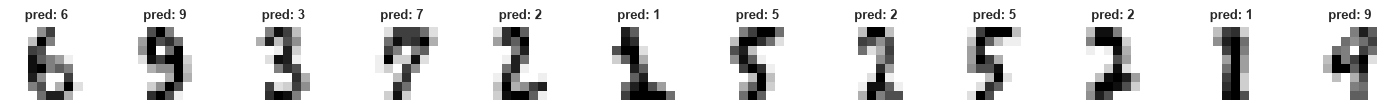

In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

digits = load_digits()                                         # 1 797 images of 8×8 pixels, bundled with scikit-learn
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=SEED)
model = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(X_train, y_train)   # learn
print(f"Accuracy on images the model has never seen: {model.score(X_test, y_test):.1%}")

preds = model.predict(X_test[:12])
show_images(X_test[:12].reshape(-1, 8, 8), titles=[f"pred: {p}" for p in preds], cmap="gray_r", ncols=12, size=1.2)

That's it: ~97% of digits recognised by a model that "looked" at 1 300 examples for one second.
Everything else in this course is about doing this **reliably**, on **harder** problems, and **knowing** how well it
will work on data you have never seen.

## 5. How the course is organised 🗺️

Each track contains two kinds of notebooks:

- 🎯 **Quests** (`*_quest_*.ipynb`): guided notebooks *to complete*. Cells marked `# TODO` are for you. Hidden
  solutions are one click away (💡 *Stuck? Click to reveal*), and `check(...)` cells tell you if you are on track.
- 🚀 **Applications** (`*_app_*.ipynb` and the others): complete, executed notebooks on real competition-style
  datasets, explained step by step. Read them, run them, then try the **Your turn** challenges at the end.

The game layer 🎮 is optional but fun: each checkpoint gives you XP, you level up from *Curious Rookie* to
*Grandmaster-in-the-making*, and you collect badges. Check your progress anytime with `progress()`.

**Suggested path:** `00_start_here` → `01_tabular` → then any track you like. Deep learning tracks (vision, NLP,
audio) assume you finished the tabular classification quest.

In [5]:
badge("First Steps", "👣", "Next stop: 01_ml_step_by_step_template.ipynb, the map every project follows.")
progress()

╔════════════════════════════════╗
║ 👣  BADGE UNLOCKED: First Steps ║
╚════════════════════════════════╝
Next stop: 01_ml_step_by_step_template.ipynb, the map every project follows.
🥚 Curious Rookie
████████████░░░░░░░░░░░░ 50/100 XP
Checkpoints unlocked: 1
Badges: 👣 First Steps
